# Team A Credit Card Fraud Detection
## Data exploration and preparation evidence

This notebook supports **Final Project Proposal Data Preparation**. Its phases cover source and sampling, schema and quality, exploratory relationships, feature engineering, chronological splitting, and preprocessing. No classifier is trained.

**Submission run:** the existing 324-card development sample, not the newer unaccepted 323-card preview. Full original files will be used for final project modeling. Raw CSVs are unchanged. Test labels are not loaded.

**Run locally:** open this notebook from Part II with its code folder, install requirements.txt, then Run All. **Colab:** open the notebook and Run All; if the CSV pair is missing, a browser asks for both reduced CSVs or ZIPs containing them. No Kaggle credentials are needed. Shared functions are imported locally; the identical source snapshot below allows the notebook to run on its own in Colab.

## Phase 1 Setup and input selection

In [1]:
from pathlib import Path
import sys, json, shutil, zipfile
import pandas as pd
from IPython.display import display, Image

USE_FULL_DATA = False  # Keep False to reproduce the submitted reduced-data results.
DATA_DIR = None  # Optional: Path(r"C:\your\csv_folder")
ORIGINAL_DIR = None  # Optional: folder containing the FULL original CSV pair for sampling audit.
OUTPUT_DIR = Path.cwd() / "evidence"
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)


In [2]:
# Shared module snapshot; authored in code/project_data.py.
MODULE_SOURCE = '"""Shared EDA and preparation functions for the Team A submission notebook."""\n\nimport hashlib\nimport json\nimport platform\nfrom pathlib import Path\n\nimport joblib\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport scipy\nfrom scipy import sparse\nimport sklearn\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\n\nTARGET = \'is_fraud\'\nNUMERIC = [\'amt\', \'city_pop\', \'lat\', \'long\', \'merch_lat\', \'merch_long\',\n           \'transaction_hour\', \'transaction_day_of_week\', \'transaction_month\',\n           \'customer_age\', \'customer_merchant_distance_km\']\nCATEGORICAL = [\'category\', \'gender\', \'state\']\nFEATURES = NUMERIC + CATEGORICAL\n\n\ndef sha256(path):\n    digest = hashlib.sha256()\n    with Path(path).open(\'rb\') as source:\n        for chunk in iter(lambda: source.read(1024 * 1024), b\'\'):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef load_data(directory):\n    directory = Path(directory)\n    train = pd.read_csv(directory/\'fraudTrain.csv\', dtype={\'cc_num\': \'string\'})\n    # Test outcomes are not loaded for EDA, preparation, or model selection.\n    test = pd.read_csv(directory/\'fraudTest.csv\', dtype={\'cc_num\': \'string\'},\n                       usecols=lambda c: c != TARGET)\n    required = {\'trans_date_trans_time\', \'dob\', \'trans_num\', \'cc_num\'} | set(FEATURES[:6]) | set(CATEGORICAL)\n    for name, frame in [(\'development\',train),(\'test\',test)]:\n        missing = required - set(frame.columns)\n        if missing or frame.empty:\n            raise ValueError(f\'{name}: empty data or missing columns {sorted(missing)}\')\n    if TARGET not in train:\n        raise ValueError(\'Development CSV must contain is_fraud\')\n    return train, test\n\n\ndef audit_sample(original_dir, sample_dir, output_dir):\n    """Verify the existing sample against original files; inspect no test labels."""\n    original_dir, sample_dir, output_dir = map(Path, (original_dir,sample_dir,output_dir))\n    report, card_sets, saved_cards = {\'splits\':{}}, {}, {}\n    for split, filename in [(\'train\',\'fraudTrain.csv\'),(\'test\',\'fraudTest.csv\')]:\n        original = pd.read_csv(original_dir/filename,usecols=[\'cc_num\'],dtype=\'string\')[\'cc_num\']\n        reduced = pd.read_csv(sample_dir/filename,usecols=[\'cc_num\'],dtype=\'string\')[\'cc_num\']\n        oc, rc = original.value_counts(), reduced.value_counts()\n        complete = bool(oc.reindex(rc.index).equals(rc))\n        if not complete:\n            raise ValueError(f\'{split}: the sample does not retain complete histories\')\n        card_sets[split], saved_cards[split] = set(original), set(reduced)\n        report[\'splits\'][split] = {\n            \'original_rows\':len(original), \'sample_rows\':len(reduced),\n            \'original_cards\':original.nunique(),\'sample_cards\':reduced.nunique(),\n            \'row_percent\':100*len(reduced)/len(original),\'complete_histories\':complete,\n            \'original_bytes\':(original_dir/filename).stat().st_size,\n            \'sample_bytes\':(sample_dir/filename).stat().st_size,\n            \'original_sha256\':sha256(original_dir/filename),\n            \'sample_sha256\':sha256(sample_dir/filename),\n        }\n    using_full = all(v[\'original_sha256\']==v[\'sample_sha256\'] for v in report[\'splits\'].values())\n    report.update({\n        \'data_mode\': \'full_originals\' if using_full else \'existing_development_sample\',\n        \'shared_original_cards\':len(card_sets[\'train\'] & card_sets[\'test\']),\n        \'test_only_original_cards\':len(card_sets[\'test\']-card_sets[\'train\']),\n        \'train_only_original_cards\':len(card_sets[\'train\']-card_sets[\'test\']),\n        \'same_selected_cards_in_both\':saved_cards[\'train\']==saved_cards[\'test\'],\n        \'existing_sample_method\': \'No sampling; full original CSV pair.\' if using_full else \'Earlier test-row-target selection; recorded seed 42; exact saved IDs audited here.\',\n        \'new_reducer_method\':\'User-specified fraction of unique TEST cards; preview saves IDs, separate write accepts them.\',\n        \'final_project_plan\':\'Use full original train and test files, including train-only cards.\',\n    })\n    full_labels = pd.read_csv(original_dir/\'fraudTrain.csv\',usecols=[TARGET])[TARGET]\n    sample_labels = pd.read_csv(sample_dir/\'fraudTrain.csv\',usecols=[TARGET])[TARGET]\n    report[\'development_fraud_comparison\'] = {\n        \'original_fraud\':int(full_labels.sum()),\'original_rate_pct\':float(full_labels.mean()*100),\n        \'sample_fraud\':int(sample_labels.sum()),\'sample_rate_pct\':float(sample_labels.mean()*100),\n    }\n    output_dir.mkdir(parents=True,exist_ok=True)\n    pd.Series(sorted(saved_cards[\'test\']),name=\'cc_num\').to_csv(output_dir/\'existing_sample_cards.csv\',index=False)\n    (output_dir/\'sampling_audit.json\').write_text(json.dumps(report,indent=2),encoding=\'utf-8\')\n    return report\n\n\ndef quality_checks(df):\n    timestamps = pd.to_datetime(df[\'trans_date_trans_time\'],errors=\'coerce\')\n    dob = pd.to_datetime(df[\'dob\'],errors=\'coerce\')\n    numeric = df[[\'amt\',\'city_pop\',\'lat\',\'long\',\'merch_lat\',\'merch_long\']].apply(pd.to_numeric,errors=\'coerce\')\n    q = {\n        \'rows\':len(df),\'columns\':len(df.columns),\'missing_cells\':int(df.isna().sum().sum()),\n        \'duplicate_rows\':int(df.duplicated().sum()),\n        \'duplicate_transaction_ids\':int(df.trans_num.duplicated().sum()),\n        \'invalid_labels\':int((~df[TARGET].isin([0,1])).sum()),\n        \'invalid_timestamps\':int(timestamps.isna().sum()),\'invalid_birth_dates\':int(dob.isna().sum()),\n        \'invalid_numeric_cells\':int((~np.isfinite(numeric)).sum().sum()),\n        \'nonpositive_amounts\':int((numeric.amt<=0).sum()),\n        \'negative_city_population\':int((numeric.city_pop<0).sum()),\n        \'birth_after_transaction\':int((dob>timestamps).sum()),\n    }\n    bad_coords = ~numeric[\'lat\'].between(-90,90) | ~numeric[\'merch_lat\'].between(-90,90) | ~numeric[\'long\'].between(-180,180) | ~numeric[\'merch_long\'].between(-180,180)\n    q[\'invalid_coordinates\'] = int(bad_coords.sum())\n    q1,q3 = df.amt.quantile([.25,.75])\n    upper = float(q3+1.5*(q3-q1))\n    q.update({\'amount_iqr_upper_fence\':upper,\'amount_upper_outliers\':int((df.amt>upper).sum()),\n              \'amount_min\':float(df.amt.min()),\'amount_max\':float(df.amt.max())})\n    schema=pd.DataFrame({\'column\':df.columns,\'dtype\':df.dtypes.astype(str).values,\n                         \'missing\':df.isna().sum().values,\'unique\':df.nunique().values})\n    return q,schema\n\n\ndef derive_features(raw):\n    df=raw.copy(deep=True)\n    timestamp=pd.to_datetime(df.trans_date_trans_time,errors=\'raise\')\n    dob=pd.to_datetime(df.dob,errors=\'raise\')\n    df[\'transaction_timestamp\']=timestamp\n    df[\'transaction_hour\']=timestamp.dt.hour\n    df[\'transaction_day_of_week\']=timestamp.dt.dayofweek\n    df[\'transaction_month\']=timestamp.dt.month\n    df[\'customer_age\']=(timestamp-dob).dt.days/365.2425\n    a,b,c,d=(np.radians(df[col].astype(float)) for col in [\'lat\',\'long\',\'merch_lat\',\'merch_long\'])\n    hav=np.sin((c-a)/2)**2+np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2\n    df[\'customer_merchant_distance_km\']=6371.0088*2*np.arcsin(np.sqrt(np.clip(hav,0,1)))\n    return df\n\n\ndef class_distribution(df):\n    result=df[TARGET].value_counts().reindex([0,1],fill_value=0).rename_axis(TARGET).to_frame(\'count\')\n    result[\'percentage\']=100*result[\'count\']/len(df)\n    return result\n\n\ndef run_eda(df, output_dir):\n    """Development data only; descriptive relationships are not causal evidence."""\n    output_dir=Path(output_dir); output_dir.mkdir(parents=True,exist_ok=True)\n    derived=derive_features(df)\n    amount=df.groupby(TARGET).amt.agg([\'count\',\'mean\',\'median\',\'min\',\'max\'])\n    category=df.groupby(\'category\')[TARGET].agg([\'size\',\'sum\',\'mean\']).rename(columns={\'size\':\'transactions\',\'sum\':\'fraud\',\'mean\':\'fraud_rate\'})\n    category[\'fraud_rate_pct\']=100*category.fraud_rate\n    hours=derived.groupby(\'transaction_hour\')[TARGET].agg([\'size\',\'sum\',\'mean\'])\n    days=derived.groupby(\'transaction_day_of_week\')[TARGET].agg([\'size\',\'sum\',\'mean\'])\n    dates={\'start\':str(derived.transaction_timestamp.min()),\'end\':str(derived.transaction_timestamp.max())}\n    for name,table in [(\'class_distribution\',class_distribution(df)),(\'amount_summary\',amount),(\'category_summary\',category),(\'hour_summary\',hours),(\'weekday_summary\',days)]:\n        table.to_csv(output_dir/f\'{name}.csv\')\n    charts={}\n    def save(fig,name):\n        fig.tight_layout(); path=output_dir/f\'{name}.png\';fig.savefig(path,dpi=160,bbox_inches=\'tight\');plt.close(fig);charts[name]=path\n    plt.rcParams.update({\'font.size\':10,\'axes.spines.top\':False,\'axes.spines.right\':False})\n    fig,ax=plt.subplots(figsize=(7,3.3));counts=class_distribution(df)[\'count\']\n    ax.bar([\'Legitimate\',\'Fraud\'],counts,color=[\'#237e78\',\'#bd4148\']);ax.set_yscale(\'log\');ax.set_ylabel(\'Transactions (log scale)\')\n    for i,n in enumerate(counts):ax.text(i,n*1.15,f\'{n:,}\',ha=\'center\')\n    ax.set_ylim(1,len(df)*2);ax.set_title(\'Development class distribution\');save(fig,\'class_distribution\')\n    fig,ax=plt.subplots(figsize=(7,3.3))\n    for value,label,color in [(0,\'Legitimate\',\'#237e78\'),(1,\'Fraud\',\'#bd4148\')]:\n        ax.hist(np.log1p(df.loc[df[TARGET]==value,\'amt\']),bins=45,density=True,histtype=\'step\',linewidth=1.8,label=label,color=color)\n    ax.set_xlabel(\'log(1 + transaction amount in USD)\');ax.set_ylabel(\'Density\');ax.legend();save(fig,\'amount_by_label\')\n    fig,ax=plt.subplots(figsize=(7,4));category.sort_values(\'fraud_rate_pct\').fraud_rate_pct.plot.barh(ax=ax,color=\'#237e78\')\n    ax.set_xlabel(\'Fraud rate (%)\');ax.set_ylabel(\'\');save(fig,\'category_fraud_rate\')\n    fig,ax=plt.subplots(figsize=(7,3.3));ax.plot(hours.index,100*hours[\'mean\'],marker=\'o\',color=\'#bd4148\')\n    ax.set_xlabel(\'Transaction hour\');ax.set_ylabel(\'Fraud rate (%)\');ax.set_xticks(range(0,24,2));save(fig,\'hour_fraud_rate\')\n    fig,ax=plt.subplots(figsize=(7,2.5));ax.boxplot(np.log1p(df.amt),vert=False);ax.set_xlabel(\'log(1 + amount in USD)\');ax.set_yticks([]);save(fig,\'amount_outliers\')\n    return {\'amount\':amount,\'category\':category,\'hours\':hours,\'days\':days,\'dates\':dates,\'charts\':charts}\n\n\ndef prepare(train_raw, test_raw, output_dir):\n    """Fit preprocessing on chronological training only. Never train a classifier."""\n    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)\n    quality,schema=quality_checks(train_raw)\n    blockers=[\'missing_cells\',\'duplicate_rows\',\'duplicate_transaction_ids\',\'invalid_labels\',\'invalid_timestamps\',\n              \'invalid_birth_dates\',\'invalid_numeric_cells\',\'nonpositive_amounts\',\'invalid_coordinates\',\n              \'negative_city_population\',\'birth_after_transaction\']\n    if any(quality[k] for k in blockers):\n        raise ValueError(\'Quality gate failed; inspect and explicitly resolve findings before preprocessing\')\n    development=derive_features(train_raw).sort_values(\'transaction_timestamp\',kind=\'stable\').reset_index(drop=True)\n    test=derive_features(test_raw).sort_values(\'transaction_timestamp\',kind=\'stable\').reset_index(drop=True)\n    boundary=int(len(development)*.8)\n    train,validation=development.iloc[:boundary],development.iloc[boundary:]\n    if train.empty or validation.empty or train[TARGET].nunique()!=2 or validation[TARGET].nunique()!=2:\n        raise ValueError(\'Training and validation need nonempty examples of both classes\')\n    if not train.transaction_timestamp.max()<=validation.transaction_timestamp.min()<test.transaction_timestamp.min():\n        raise ValueError(\'Chronology checks failed\')\n    if not validation.transaction_timestamp.max()<test.transaction_timestamp.min():\n        raise ValueError(\'Validation and test periods overlap\')\n    if set(development.trans_num)&set(test.trans_num):\n        raise ValueError(\'Development and test transaction IDs overlap\')\n    for name,frame in [(\'training\',train),(\'validation\',validation),(\'test\',test)]:\n        if frame[FEATURES].isna().any().any() or not np.isfinite(frame[NUMERIC].to_numpy(dtype=float)).all():\n            raise ValueError(f\'{name}: incomplete or non-finite features\')\n    transformer=ColumnTransformer([\n        (\'numeric\',StandardScaler(),NUMERIC),\n        (\'categorical\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=True),CATEGORICAL)],\n        sparse_threshold=1.0,verbose_feature_names_out=True)\n    matrices={\'training\':transformer.fit_transform(train[FEATURES]),\n              \'validation\':transformer.transform(validation[FEATURES]),\'test\':transformer.transform(test[FEATURES])}\n    names=transformer.get_feature_names_out()\n    rows=[]\n    total=len(development)+len(test)\n    for name,frame in [(\'Training\',train),(\'Validation\',validation),(\'Final test\',test)]:\n        rows.append({\'split\':name,\'rows\':len(frame),\'percent_of_all\':100*len(frame)/total,\n                     \'start\':str(frame.transaction_timestamp.min()),\'end\':str(frame.transaction_timestamp.max()),\n                     \'fraud\':int(frame[TARGET].sum()) if name!=\'Final test\' else \'Reserved\'})\n    splits=pd.DataFrame(rows)\n    example_cols=[\'trans_date_trans_time\',\'category\',\'amt\',\'gender\',\'state\',\'city_pop\',\'dob\',\'lat\',\'long\',\'merch_lat\',\'merch_long\',TARGET]\n    before=validation.iloc[[0]][example_cols]\n    vector=matrices[\'validation\'][0].toarray().ravel()\n    active=np.flatnonzero(vector)\n    after=pd.DataFrame({\'feature\':names[active],\'value\':vector[active]})\n    original_card_sets={name:set(frame.cc_num) for name,frame in [(\'training\',train),(\'validation\',validation),(\'test\',test)]}\n    info={\n        \'quality\':quality,\'class_distribution\':class_distribution(train_raw).reset_index().to_dict(\'records\'),\n        \'cleaning\':{\'before\':len(train_raw),\'removed\':0,\'added\':0,\'after\':len(train_raw)},\n        \'split_summary\':rows,\'numeric_features\':NUMERIC,\'categorical_features\':CATEGORICAL,\n        \'feature_count\':len(names),\'matrix_shapes\':{k:list(v.shape) for k,v in matrices.items()},\n        \'test_labels_loaded\':False,\'cross_file_duplicate_transaction_ids\':0,\n        \'test_cards_unseen_in_training_split\':len(original_card_sets[\'test\']-original_card_sets[\'training\']),\n        \'environment\':{\'python\':platform.python_version(),\'pandas\':pd.__version__,\'numpy\':np.__version__,\n                       \'scipy\':scipy.__version__,\'scikit_learn\':sklearn.__version__,\'matplotlib\':matplotlib.__version__,\'joblib\':joblib.__version__},\n    }\n    schema.to_csv(output_dir/\'schema.csv\',index=False)\n    splits.to_csv(output_dir/\'split_summary.csv\',index=False)\n    before.to_csv(output_dir/\'before_preprocessing.csv\',index=False)\n    after.to_csv(output_dir/\'after_preprocessing.csv\',index=False)\n    pd.Series(names,name=\'feature\').to_csv(output_dir/\'feature_names.csv\',index=False)\n    joblib.dump(transformer,output_dir/\'preprocessor.joblib\')\n    (output_dir/\'preparation_evidence.json\').write_text(json.dumps(info,indent=2),encoding=\'utf-8\')\n    return info, splits, before, after, matrices\n'
module_dir = Path.cwd() / 'code'
if not (module_dir / 'project_data.py').is_file():
    module_dir = Path('/content/team_a_code') if IN_COLAB else Path.cwd() / '.notebook_code'
    module_dir.mkdir(parents=True, exist_ok=True)
    (module_dir / 'project_data.py').write_text(MODULE_SOURCE, encoding='utf-8')
sys.path.insert(0, str(module_dir.resolve()))
from project_data import load_data, audit_sample, quality_checks, run_eda, prepare, class_distribution
print('Shared functions:', module_dir.resolve())


Shared functions: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\Part II\code


In [3]:
roots = [Path.cwd(), *list(Path.cwd().parents)[:3]]
if DATA_DIR is None:
    candidates = []
    for root in roots:
        candidates += [root/'fraud' if USE_FULL_DATA else root/'fraud/reduced']
    candidates += [Path('/content/data'), Path('/content'), Path.cwd()]
    DATA_DIR = next((p for p in candidates if (p/'fraudTrain.csv').is_file() and (p/'fraudTest.csv').is_file()), None)
if DATA_DIR is None and IN_COLAB:
    print('Browse for BOTH development and test CSVs, or ZIPs containing them.')
    uploaded = files.upload()
    DATA_DIR = Path('/content/team_a_uploaded_data')
    DATA_DIR.mkdir(exist_ok=True)
    for name in uploaded:
        source_path = Path(name)
        if source_path.suffix.lower()=='.zip':
            with zipfile.ZipFile(source_path) as archive:
                for member in archive.infolist():
                    if Path(member.filename).name in {'fraudTrain.csv','fraudTest.csv'}:
                        destination = DATA_DIR/Path(member.filename).name
                        if destination.exists(): raise ValueError('Duplicate CSV supplied; provide one pair only.')
                        with archive.open(member) as src, destination.open('wb') as dst:
                            shutil.copyfileobj(src,dst)
        elif source_path.name in {'fraudTrain.csv','fraudTest.csv'}:
            shutil.copy2(source_path,DATA_DIR/source_path.name)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing both CSVs.')
DATA_DIR=Path(DATA_DIR).resolve()
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
if ORIGINAL_DIR is None:
    ORIGINAL_DIR=next((r/'fraud' for r in roots if (r/'fraud/fraudTrain.csv').is_file()),None)
raw_df, test_inputs = load_data(DATA_DIR)
print('Data folder:', DATA_DIR)
print('Development:', raw_df.shape, 'Test inputs (label excluded):', test_inputs.shape)
print('Actual raw columns:', raw_df.columns.tolist())
print('Target: is_fraud; 0 = legitimate, 1 = fraudulent; never included as input.')
display(raw_df[['trans_date_trans_time','category','amt','state','is_fraud']].head(5))


Data folder: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\fraud\reduced
Development: (453733, 23) Test inputs (label excluded): (194320, 22)
Actual raw columns: ['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']
Target: is_fraud; 0 = legitimate, 1 = fraudulent; never included as input.


,trans_date_trans_time,category,amt,state,is_fraud
0,2019-01-01 00:00:18,misc_net,4.97,NC,0
1,2019-01-01 00:00:51,entertainment,220.11,ID,0
2,2019-01-01 00:04:42,grocery_net,44.54,KS,0
3,2019-01-01 00:05:08,gas_transport,71.65,VA,0
4,2019-01-01 00:05:18,misc_pos,4.27,PA,0


## Phase 2 Source and sampling

Dataset: [Kartik2112 Sparkov-generated transactions](https://www.kaggle.com/datasets/kartik2112/fraud-detection), version 1, updated August 5, 2020, CC0: Public Domain (metadata verified October 15, 2026). Generator: [Sparkov](https://github.com/namebrandon/Sparkov_Data_Generation). The dataset was downloaded previously; the exact original download date was not recorded.

The existing sample targeted about 35% of TEST ROWS while keeping whole cards, with seed 42 reported in the earlier project log. The audit below saves exact current IDs and verifies complete histories; it does not claim that the new reducer regenerates that old draw. The newer reducer selects a parameterized percentage of unique TEST CARDS, saves IDs/counts during preview, then writes only on acceptance. A preview may exclude train-only cards. All cards will be included when full files are used for final modeling.

The preview process does not examine fraud labels. New sampling belongs in a separate deliberate phase, not every Run All. From Part II: `python code/reduce_fraud_by_card.py preview --train ../fraud/fraudTrain.csv --test ../fraud/fraudTest.csv --percent 35`. The printed write command accepts that saved selection. Repeated previews draw again unless a seed is supplied.

In [4]:
if ORIGINAL_DIR is not None:
    sampling = audit_sample(ORIGINAL_DIR,DATA_DIR,OUTPUT_DIR)
    display(pd.DataFrame(sampling['splits']).T)
    print('Original card coverage:', {k:sampling[k] for k in ['shared_original_cards','test_only_original_cards','train_only_original_cards']})
    print('Development fraud-rate comparison:',sampling['development_fraud_comparison'])
else:
    sampling = None
    print('Original files not supplied: sampling comparison skipped. Supply ORIGINAL_DIR to verify it.')


,original_rows,sample_rows,original_cards,sample_cards,row_percent,complete_histories,original_bytes,sample_bytes,original_sha256,sample_sha256
train,1296675,453733,983,324,34.992037,True,351238196,122432070,fd7139200dbfcbed0b6742bbe05a4f1abce532c4fef209...,230543eccd9dab6124dfc668991fd474751615eb522609...
test,555719,194320,924,324,34.967313,True,150354339,52368280,12d553ab19440c752d2531ee1af44bb64f12cc3d3839f1...,39d06838f4a1ae7eb8f2db49711bde1ad78d2565af54c1...


Original card coverage: {'shared_original_cards': 908, 'test_only_original_cards': 16, 'train_only_original_cards': 75}
Development fraud-rate comparison: {'original_fraud': 7506, 'original_rate_pct': 0.5788651743883394, 'sample_fraud': 2437, 'sample_rate_pct': 0.5371000125624541}


## Phase 3 Schema and quality checks

In [5]:
quality,schema=quality_checks(raw_df)
display(schema)
display(pd.Series(quality,name='observed').to_frame())
print('Large amounts above the IQR fence are flagged for review, not automatically deleted.')
print('Date strings are parsed in derived copies; direct identifiers and index fields stay out of model inputs.')


,column,dtype,missing,unique
0,Unnamed: 0,int64,0,453733
1,trans_date_trans_time,str,0,451067
2,cc_num,string,0,324
3,merchant,str,0,693
4,category,str,0,14
5,amt,float64,0,35036
6,first,str,0,191
7,last,str,0,232
8,gender,str,0,2
9,street,str,0,324


,observed
rows,453733.000
columns,23.000
missing_cells,0.000
duplicate_rows,0.000
duplicate_transaction_ids,0.000
invalid_labels,0.000
invalid_timestamps,0.000
invalid_birth_dates,0.000
invalid_numeric_cells,0.000
nonpositive_amounts,0.000


Large amounts above the IQR fence are flagged for review, not automatically deleted.
Date strings are parsed in derived copies; direct identifiers and index fields stay out of model inputs.


## Phase 4 Exploratory relationships

All plots use development transactions only. Amount, category, and time relationships are descriptive associations, not proof of fraud or causal effects. These exploratory choices have seen the development period, including the later validation portion; validation is therefore a development measure, not untouched final evidence. The official test outcomes remain reserved.

,count,percentage
is_fraud,,
0,451296,99.4629
1,2437,0.5371


,count,mean,median,min,max
is_fraud,,,,,
0,451296,67.878319,48.43,1.00,27119.77
1,2437,514.079196,353.88,1.91,1371.81


,transactions,fraud,fraud_rate,fraud_rate_pct
category,,,,
shopping_net,33764,536,0.015875,1.587490
misc_net,21800,293,0.013440,1.344037
grocery_pos,43695,574,0.013137,1.313651
shopping_pos,40748,244,0.005988,0.598802
gas_transport,45696,208,0.004552,0.455182
grocery_net,15951,52,0.003260,0.325998
misc_pos,28318,89,0.003143,0.314288
travel,14105,34,0.002410,0.241049
personal_care,31628,76,0.002403,0.240293


Development period: {'start': '2019-01-01 00:00:18', 'end': '2020-06-21 12:13:36'}
class_distribution


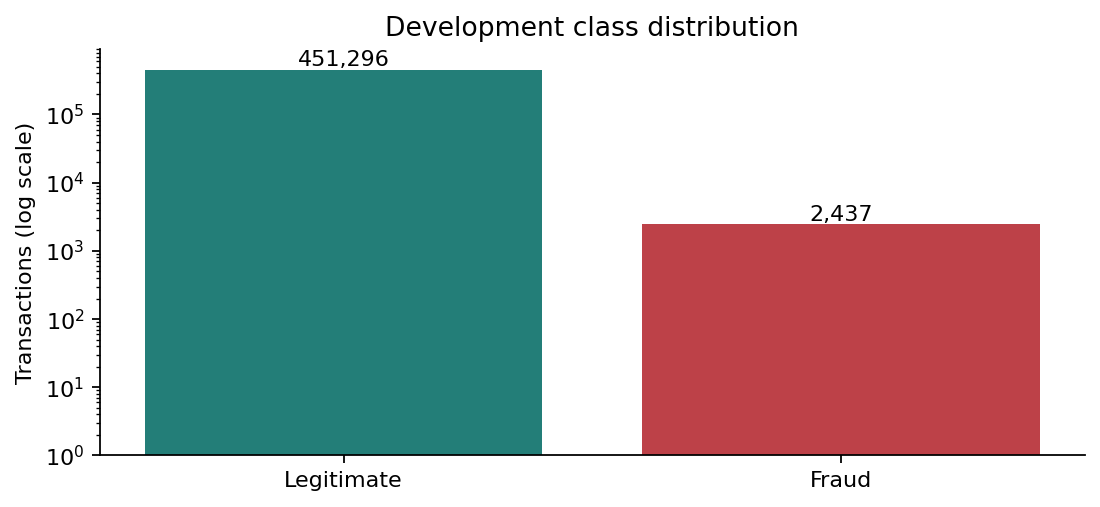

amount_by_label


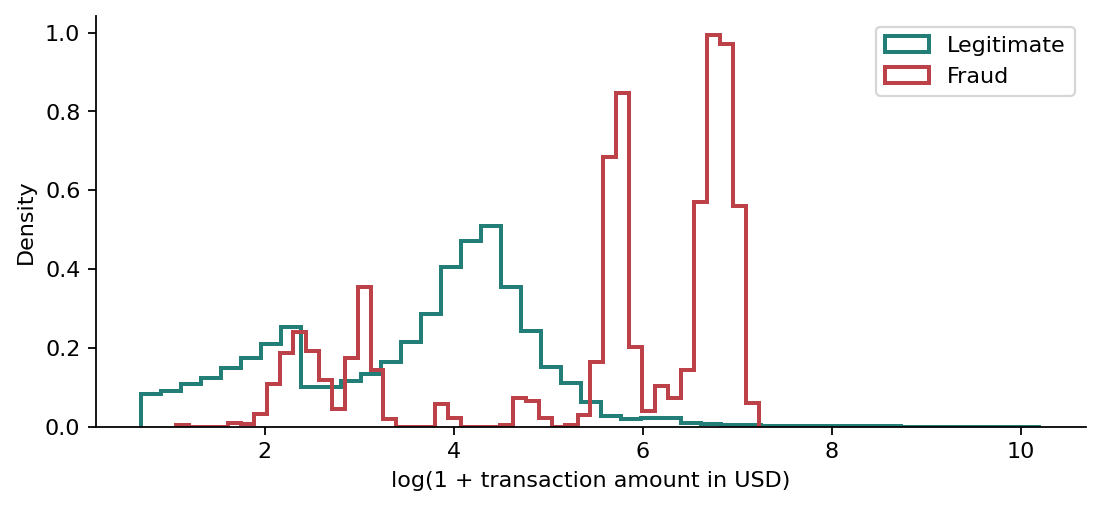

category_fraud_rate


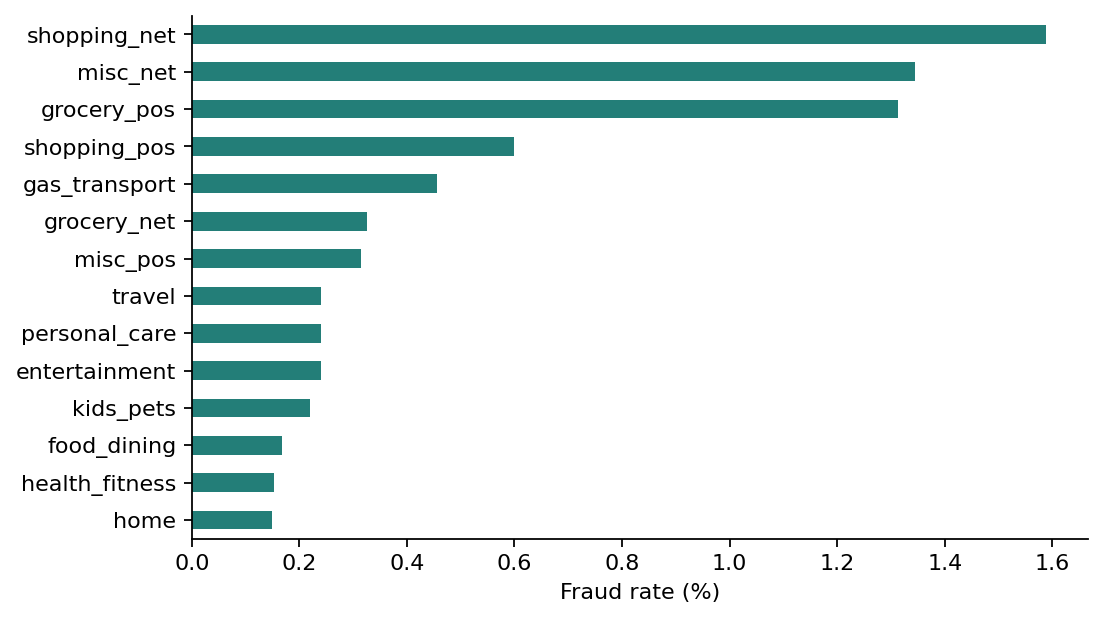

hour_fraud_rate


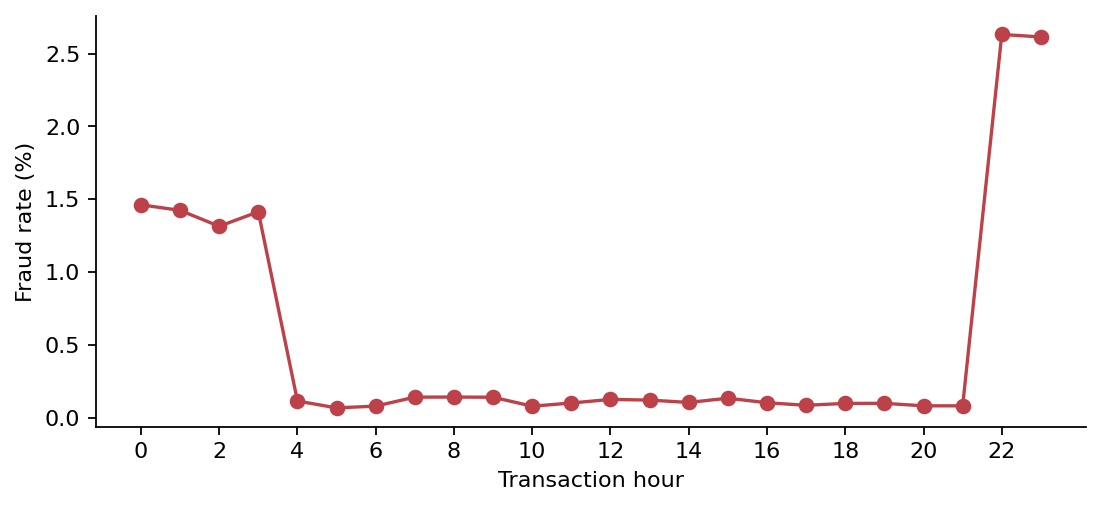

amount_outliers


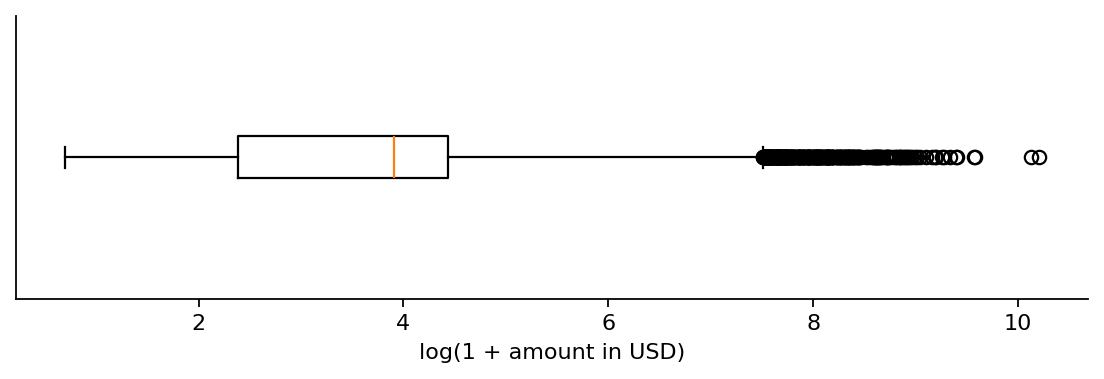

In [6]:
eda=run_eda(raw_df,OUTPUT_DIR)
display(class_distribution(raw_df))
display(eda['amount'])
display(eda['category'].sort_values('fraud_rate_pct',ascending=False))
print('Development period:',eda['dates'])
for title,path in eda['charts'].items():
    print(title)
    display(Image(filename=str(path)))


### Interpreting the findings

The class table exposes severe imbalance: accuracy alone would reward a classifier that misses all fraud. Compare precision, recall, PR-AUC, and review workload during modeling. Higher category/hour rates can help prioritize feature candidates but do not mean all transactions in those groups are fraudulent. Synthetic U.S. behavior, binary gender coding, geography, repeated customers, and card sampling constrain representativeness. High amounts may be meaningful fraud signals; retain valid extremes.

## Phase 5 Cleaning decisions and derived features

In [7]:
from project_data import derive_features
derived=derive_features(raw_df)
display(derived[['amt','transaction_hour','transaction_day_of_week','transaction_month','customer_age','customer_merchant_distance_km']].head())
print('Raw date type remains:',raw_df['trans_date_trans_time'].dtype)
display(class_distribution(raw_df))
print('The quality gate below stops on defects instead of silently dropping or imputing rows.')


,amt,transaction_hour,transaction_day_of_week,transaction_month,customer_age,customer_merchant_distance_km
0,4.97,0,1,1,30.815143,78.597677
1,220.11,0,1,1,56.951204,108.206232
2,44.54,0,1,1,25.377660,118.119939
3,71.65,0,1,1,71.366284,12.766940
4,4.27,0,1,1,77.822269,25.270529


Raw date type remains: str


,count,percentage
is_fraud,,
0,451296,99.4629
1,2437,0.5371


The quality gate below stops on defects instead of silently dropping or imputing rows.


## Phase 6 Fair splits and preprocessing

Sort development records by transaction timestamp; use the earliest 80% for training and latest 20% for validation. Retain the official later test period. Cards can overlap across periods: this evaluates future transactions, not purely new customers. Direct identifiers are excluded, and transaction IDs must not overlap across development and test.

Fit numeric scaling and category/gender/state one-hot encoding on TRAINING ONLY. Unknown later categories are ignored. There is no oversampling, model training, threshold selection, or test-label evaluation here. Numeric time fields are an explainable first pass; cyclical representations and feature ablations are future modeling comparisons.

In [8]:
info,splits,before,after,matrices=prepare(raw_df,test_inputs,OUTPUT_DIR)
display(splits)
display(pd.DataFrame(info['matrix_shapes'],index=['rows','features']).T)
print('Model features:', info['numeric_features'], '+',info['categorical_features'])
print('Both CSV files remain unchanged; test labels loaded:',info['test_labels_loaded'])
print('Library versions:',info['environment'])


,split,rows,percent_of_all,start,end,fraud
0,Training,362986,56.011777,2019-01-01 00:00:18,2020-03-06 13:39:47,1843
1,Validation,90747,14.003021,2020-03-06 13:44:38,2020-06-21 12:13:36,594
2,Final test,194320,29.985202,2020-06-21 12:14:53,2020-12-31 23:56:57,Reserved


,rows,features
training,362986,73
validation,90747,73
test,194320,73


Model features: ['amt', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long', 'transaction_hour', 'transaction_day_of_week', 'transaction_month', 'customer_age', 'customer_merchant_distance_km'] + ['category', 'gender', 'state']
Both CSV files remain unchanged; test labels loaded: False
Library versions: {'python': '3.12.0', 'pandas': '3.0.3', 'numpy': '2.5.4', 'scipy': '1.16.3', 'scikit_learn': '1.8.0', 'matplotlib': '3.10.8', 'joblib': '1.5.3'}


## Phase 7 Actual before and after evidence

In [9]:
display(before.T.rename(columns={before.index[0]:'raw_value'}))
display(after)
display(pd.Series(info['cleaning'],name='records').to_frame())
print('Zero rows removed when quality checks pass; sampling exclusions are not cleaning removals.')
print('Evidence directory:', OUTPUT_DIR.resolve())
print('\n'.join(p.name for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()))


,raw_value
trans_date_trans_time,2020-03-06 13:44:38
category,personal_care
amt,74.05
gender,F
state,KY
city_pop,14228
dob,1971-03-26
lat,38.6207
long,-83.8067
merch_lat,39.028155


,feature,value
0,numeric__amt,0.025932
1,numeric__city_pop,-0.232292
2,numeric__lat,0.102641
3,numeric__long,0.488338
4,numeric__merch_lat,0.184829
5,numeric__merch_long,0.444684
6,numeric__transaction_hour,0.026103
7,numeric__transaction_day_of_week,0.393876
8,numeric__transaction_month,-0.968038
9,numeric__customer_age,0.272091


,records
before,453733
removed,0
added,0
after,453733


Zero rows removed when quality checks pass; sampling exclusions are not cleaning removals.
Evidence directory: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\Part II\evidence
after_preprocessing.csv
amount_by_label.png
amount_outliers.png
amount_summary.csv
before_preprocessing.csv
category_fraud_rate.png
category_summary.csv
class_distribution.csv
class_distribution.png
existing_sample_cards.csv
feature_names.csv
hour_fraud_rate.png
hour_summary.csv
preparation_evidence.json
preprocessor.joblib
sampling_audit.json
schema.csv
split_summary.csv
weekday_summary.csv


## Phase 8 Readiness and final project plan

Ready with limitations for classroom model development. Next compare a majority baseline, a simple amount rule, Logistic Regression, and a tree classifier; choose thresholds on validation only. Use full original files for final project modeling so train-only cards are retained. Rerun this preparation with `USE_FULL_DATA=True` and a distinct output directory before modeling, and update counts in later reports. This submitted run remains the documented reduced-data run.

To reproduce this existing sample from originals, filter both files using `evidence/existing_sample_cards.csv`. The new reducer's separate previews are not approved replacements. Generated evidence includes sampling fingerprints, exact IDs, source/schema counts, plots, real transformations, and the fitted preprocessor. The `.joblib` artifact is preprocessing, not a trained fraud classifier.